# Пример: Электрометрия

Четыре расчёта к серии об электрометрии: измерение скалярных произведений, восстановление геометрии электродов, влияние внутренней связи и восстановление проводимости слоёв. Первый и третий расчёты выполняются в точной арифметике; второй и четвёртый используют численные методы.

[Электрометрия](https://github.com/magin67/pmg-notes/blob/v5/pmg-library/ru/%D0%A0%D0%B5%D0%B7%D0%B8%D1%81%D1%82%D0%B8%D0%B2%D0%BD%D0%B0%D1%8F%20%D0%B3%D0%B5%D0%BE%D0%BC%D0%B5%D1%82%D1%80%D0%B8%D1%8F%20%D0%B8%20%D0%B4%D1%83%D0%B0%D0%BB%D1%8C%D0%BD%D0%BE%D1%81%D1%82%D1%8C/%D0%AD%D0%BB%D0%B5%D0%BA%D1%82%D1%80%D0%BE%D0%BC%D0%B5%D1%82%D1%80%D0%B8%D1%8F/%D0%AD%D0%BB%D0%B5%D0%BA%D1%82%D1%80%D0%BE%D0%BC%D0%B5%D1%82%D1%80%D0%B8%D1%8F.md) · [English](https://github.com/magin67/pmg-notes/blob/v5/pmg-library/en/PythonExamples/Example%20-%20Electrometry.md)

[Открыть в Colab](https://colab.research.google.com/github/magin67/pmg-notes/blob/v5/pmg-library/ru/PythonExamples/notebooks/electrometry.ipynb) · [Скачать блокнот](https://raw.githubusercontent.com/magin67/pmg-notes/v5/pmg-library/ru/PythonExamples/notebooks/electrometry.ipynb)

## Подготовка

Фрагменты выполняются сверху вниз. Проверено на Python 3.12 с закреплённым коммитом `polyform_algebra` и указанными версиями основных численных пакетов. Блокнот содержит те же расчёты, исходную таблицу измерений, код рисунков и сохранённые результаты. В заметке таблица загружается по постоянной ссылке. Для локального запуска достаточно обычных Python-фрагментов; установочная ячейка с `%pip` предназначена для Jupyter и Colab.

[polyform-algebra 63d3424](https://github.com/magin67/polyform_algebra/commit/63d342437b0d5973f38befc5183d7f4ea9ecf6f0)

In [1]:
import importlib.metadata as metadata
import json

PACKAGE_URL = "https://github.com/magin67/polyform_algebra/archive/63d342437b0d5973f38befc5183d7f4ea9ecf6f0.zip"
REQUIRED = {"numpy": "2.3.5", "scipy": "1.17.0", "sympy": "1.14.0", "matplotlib": "3.10.8"}
try:
    source = json.loads(metadata.distribution("polyform_algebra").read_text("direct_url.json") or "{}")
    ready = source.get("url") == PACKAGE_URL and all(metadata.version(k) == v for k, v in REQUIRED.items())
except metadata.PackageNotFoundError:
    ready = False
if not ready:
    %pip install -q "https://github.com/magin67/polyform_algebra/archive/63d342437b0d5973f38befc5183d7f4ea9ecf6f0.zip" "numpy==2.3.5" "scipy==1.17.0" "sympy==1.14.0" "matplotlib==3.10.8"
print("Required package revision and numerical dependencies are installed.")

Required package revision and numerical dependencies are installed.


In [2]:
import csv
import io
from fractions import Fraction as Q
from itertools import combinations, product
from string import ascii_lowercase

import numpy as np
import scipy
import sympy as sp
import matplotlib
import matplotlib.pyplot as plt
from scipy.linalg import cho_factor, cho_solve
from scipy.optimize import least_squares
from polyform_algebra.core import (
    coordinates, dirichlet, gram, green, inner_product,
    kron_reduce, laplacian, network, resistance,
)
from polyform_algebra.variations import vary_conductances

np.set_printoptions(precision=6, suppress=True)
plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 10,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "figure.dpi": 110, "savefig.dpi": 130})
print("NumPy", np.__version__, "SciPy", scipy.__version__,
      "SymPy", sp.__version__, "Matplotlib", matplotlib.__version__)

def segment(net, a, b):
    # PMG orientation: (ab) = b - a; both factors change sign for unit currents.
    return coordinates(net.context, {
        v: int(v == b) - int(v == a) for v in net.context.labels
    })

NumPy 2.3.5 SciPy 1.17.0 SymPy 1.14.0 Matplotlib 3.10.8


In [3]:
%matplotlib inline
TEXT = {'original': 'Исходная сетка', 'two_modes': 'По двум модам', 'grid_x': 'Шаги сетки по x', 'grid_y': 'Шаги сетки по y', 'geometry_title': 'Совмещение сеток: RMS = 0,232 шага', 'mode': 'Номер моды (по убыванию)', 'eigenvalue': 'Собственное значение Gd', 'spectrum_title': 'Спектр после двойного центрирования', 'truth': 'Заданная среда', 'estimate': 'Восстановление', 'noisy': '4 неизвестных слоя', 'known': 'Нижний слой известен', 'prior': 'Штраф к фону, λ = 1', 'conductivity': 'Проводимость θ', 'layer': 'Номер слоя от поверхности', 'layers_title': 'Одинаковые 120 измерений с шумом 0,1%'}

No event loop hook running.


## Обозначения и функции

| Величина | Смысл | В коде |
| --- | --- | --- |
| $R_{ij}$ | Эффективный резистенс конечной сети | `resistance(net)` |
| $T_{ab,mn}$ | Четырёхэлектродное показание $(\varphi_m-\varphi_n)/I$ | `inner_product(net, ab, mn)` |
| $Z_{ij}$ | Парные коэффициенты реальной площадки | Исходный CSV; не передаются как резистенсы сети |
| $G_d$ | Двойное центрирование таблицы $D_{ij}=1/Z_{ij}^2$ | `-0.5 * J @ D @ J` |
| $K=L_{\partial}$ | Лапласиан эквивалентной сети на электродах | `laplacian(kron_reduce(...).value.network)` |
| $S$ | Чувствительность резистенсов к величинам связей, с вынесенным минусом | Квадраты элементов `gram(...)` |

Здесь $G_d$ описывает геометрию преобразованных парных данных. Это не гриниан сети. В третьем и четвёртом расчётах доступны полные модельные значения $R$; первый расчёт объясняет, почему их нельзя автоматически считать известными по опытам на четырёх различных электродах.

## Что определяют четыре электрода

Для заданной сети сравниваются скалярное произведение и формула

$$
T_{ab,mn}=\frac12(R_{an}+R_{bm}-R_{am}-R_{bn}).
$$

На четырёх различных электродах имеются три разбиения на питающую и измерительную пары. Матрица `M` переводит шесть парных значений $R$ в эти три показания. Проверяется её ранг и нечувствительность к добавкам $\varepsilon_i+\varepsilon_j$ при $i\ne j$; диагональ остаётся нулевой.


[Соответствующая заметка](https://github.com/magin67/pmg-notes/blob/v5/pmg-library/ru/%D0%A0%D0%B5%D0%B7%D0%B8%D1%81%D1%82%D0%B8%D0%B2%D0%BD%D0%B0%D1%8F%20%D0%B3%D0%B5%D0%BE%D0%BC%D0%B5%D1%82%D1%80%D0%B8%D1%8F%20%D0%B8%20%D0%B4%D1%83%D0%B0%D0%BB%D1%8C%D0%BD%D0%BE%D1%81%D1%82%D1%8C/%D0%AD%D0%BB%D0%B5%D0%BA%D1%82%D1%80%D0%BE%D0%BC%D0%B5%D1%82%D1%80%D0%B8%D1%8F/%D0%A7%D1%82%D0%BE%20%D0%B8%D0%B7%D0%BC%D0%B5%D1%80%D1%8F%D0%B5%D1%82%20%D1%8D%D0%BB%D0%B5%D0%BA%D1%82%D1%80%D0%BE%D0%BC%D0%B5%D1%82%D1%80%D0%B8%D1%8F.md).

In [4]:
electrodes = tuple("abcd")
four = network(electrodes, [
    ("a", "b", 2), ("b", "c", 1), ("c", "d", 3),
    ("d", "a", 1), ("a", "c", Q(1, 2)),
])
R = sp.Matrix(resistance(four).value.values)
pairs4 = tuple(combinations(range(4), 2))
pairings = ((0, 1, 2, 3), (0, 2, 1, 3), (0, 3, 1, 2))
measurement_rows, measured = [], []
for a, b, m, n in pairings:
    scalar = inner_product(four, segment(four, electrodes[a], electrodes[b]),
                           segment(four, electrodes[m], electrodes[n])).value
    formula = (R[a, n] + R[b, m] - R[a, m] - R[b, n]) / 2
    assert scalar == formula
    row = [Q(0) for _ in pairs4]
    for i, j, sign in ((a, n, 1), (b, m, 1), (a, m, -1), (b, n, -1)):
        row[pairs4.index(tuple(sorted((i, j))))] += Q(sign, 2)
    measurement_rows.append(row)
    measured.append(scalar)
M = sp.Matrix(measurement_rows)
assert M.rank() == 2 and measured[0] - measured[1] + measured[2] == 0
# Each column adds epsilon_i + epsilon_j to an off-diagonal pair entry.
vertex_additions = sp.Matrix([[int(k == i) + int(k == j) for k in range(4)]
                             for i, j in pairs4])
assert M * vertex_additions == sp.zeros(3, 4)
assert vertex_additions.rank() == 4
print("T_ab,cd; T_ac,bd; T_ad,bc =", measured)
print("rank(M) =", M.rank(), "; dim ker(M) =", len(pairs4) - M.rank())

T_ab,cd; T_ac,bd; T_ad,bc = [Fraction(-1, 23), Fraction(5, 23), Fraction(6, 23)]
rank(M) = 2 ; dim ker(M) = 4


Получаются $T_{ab,cd}=-1/23$, $T_{ac,bd}=5/23$, $T_{ad,bc}=6/23$. Выполняется $T_{ab,cd}-T_{ac,bd}+T_{ad,bc}=0$. Ранг равен 2, размерность ядра равна 4. Это проверка на произвольных парных координатах, а не утверждение о независимости параметров конкретного грунта. Контактные добавки отдельно разобраны в [примере KVP-разложения](https://github.com/magin67/pmg-notes/blob/v5/pmg-library/ru/PythonExamples/%D0%9F%D1%80%D0%B8%D0%BC%D0%B5%D1%80%20-%20KVP-%D1%80%D0%B0%D0%B7%D0%BB%D0%BE%D0%B6%D0%B5%D0%BD%D0%B8%D0%B5.md#%D0%BA%D0%BE%D0%BD%D1%82%D0%B0%D0%BA%D1%82%D1%8B-%D0%B8-%D0%B8%D0%B7%D0%BC%D0%B5%D0%BD%D0%B5%D0%BD%D0%B8%D0%B5-%D0%BF%D1%80%D0%BE%D0%B2%D0%BE%D0%B4%D0%B8%D0%BC%D0%BE%D1%81%D1%82%D0%B8).

## Геометрия по реальным парным данным

Используется опубликованная в серии таблица: 16 электродов, 120 пар. Координаты даны в шагах сетки, значения `Z` сохранены в масштабе исходных данных. Сопоставление геометрии допускает один общий масштаб, перенос и ортогональное преобразование. Значения координат не используются при выделении двух мод; они нужны для совмещения и оценки ошибки.

Блокнот содержит копию CSV. Контрольная сумма вычисляется после приведения переводов строк к `LF`.

[Соответствующая заметка](https://github.com/magin67/pmg-notes/blob/v5/pmg-library/ru/%D0%A0%D0%B5%D0%B7%D0%B8%D1%81%D1%82%D0%B8%D0%B2%D0%BD%D0%B0%D1%8F%20%D0%B3%D0%B5%D0%BE%D0%BC%D0%B5%D1%82%D1%80%D0%B8%D1%8F%20%D0%B8%20%D0%B4%D1%83%D0%B0%D0%BB%D1%8C%D0%BD%D0%BE%D1%81%D1%82%D1%8C/%D0%AD%D0%BB%D0%B5%D0%BA%D1%82%D1%80%D0%BE%D0%BC%D0%B5%D1%82%D1%80%D0%B8%D1%8F/%D0%A1%D0%B2%D0%BE%D0%B9%D1%81%D1%82%D0%B2%D0%B0%20%D1%80%D0%B5%D0%B7%D0%B8%D1%81%D1%82%D0%B5%D0%BD%D1%81%D0%BE%D0%B2%20%D0%B2%20%D1%81%D0%BF%D0%BB%D0%BE%D1%88%D0%BD%D0%BE%D0%B9%20%D1%81%D1%80%D0%B5%D0%B4%D0%B5.md).

[CSV](https://github.com/magin67/pmg-notes/blob/f27cf204e671da5381df2c370aed70cc14d5e4ac/pmg-library/ru/%D0%A0%D0%B5%D0%B7%D0%B8%D1%81%D1%82%D0%B8%D0%B2%D0%BD%D0%B0%D1%8F%20%D0%B3%D0%B5%D0%BE%D0%BC%D0%B5%D1%82%D1%80%D0%B8%D1%8F%20%D0%B8%20%D0%B4%D1%83%D0%B0%D0%BB%D1%8C%D0%BD%D0%BE%D1%81%D1%82%D1%8C/%D0%AD%D0%BB%D0%B5%D0%BA%D1%82%D1%80%D0%BE%D0%BC%D0%B5%D1%82%D1%80%D0%B8%D1%8F/data/%D0%98%D0%B7%D0%BC%D0%B5%D1%80%D0%B5%D0%BD%D0%B8%D1%8F%20%D1%83%D1%87%D0%B0%D1%81%D1%82%D0%BA%D0%B0%204%20%D0%BD%D0%B0%204.csv).

In [5]:
DATA_CSV = """id1,id2,x1,y1,x2,y2,Z
1,2,0,0,1,0,7.47
1,3,0,0,2,0,2.8
1,4,0,0,3,0,1.45
1,14,0,0,0,1,9.01
1,15,0,0,1,1,4.74
1,16,0,0,2,1,2.32
1,17,0,0,3,1,1.29
1,27,0,0,0,2,2.93
1,28,0,0,1,2,2.43
1,29,0,0,2,2,1.65
1,30,0,0,3,2,1.06
1,40,0,0,0,3,1.51
1,41,0,0,1,3,1.38
1,42,0,0,2,3,1.03
1,43,0,0,3,3,0.75
2,3,1,0,2,0,8.2
2,4,1,0,3,0,2.95
2,14,1,0,0,1,4.67
2,15,1,0,1,1,7.15
2,16,1,0,2,1,4.53
2,17,1,0,3,1,2.29
2,27,1,0,0,2,2.26
2,28,1,0,1,2,2.75
2,29,1,0,2,2,2.36
2,30,1,0,3,2,1.61
2,40,1,0,0,3,1.3
2,41,1,0,1,3,1.44
2,42,1,0,2,3,1.26
2,43,1,0,3,3,0.99
3,4,2,0,3,0,8.21
3,14,2,0,0,1,2.39
3,15,2,0,1,1,4.84
3,16,2,0,2,1,7.94
3,17,2,0,3,1,4.61
3,27,2,0,0,2,1.6
3,28,2,0,1,2,2.44
3,29,2,0,2,2,2.96
3,30,2,0,3,2,2.43
3,40,2,0,0,3,1.07
3,41,2,0,1,3,1.37
3,42,2,0,2,3,1.43
3,43,2,0,3,3,1.28
4,14,3,0,0,1,1.35
4,15,3,0,1,1,2.44
4,16,3,0,2,1,4.9
4,17,3,0,3,1,6.96
4,27,3,0,0,2,1.05
4,28,3,0,1,2,1.64
4,29,3,0,2,2,2.43
4,30,3,0,3,2,2.78
4,40,3,0,0,3,0.79
4,41,3,0,1,3,1.06
4,42,3,0,2,3,1.28
4,43,3,0,3,3,1.39
14,15,0,1,1,1,7.52
14,16,0,1,2,1,2.79
14,17,0,1,3,1,1.44
14,27,0,1,0,2,7.2
14,28,0,1,1,2,4.55
14,29,0,1,2,2,2.36
14,30,0,1,3,2,1.33
14,40,0,1,0,3,2.74
14,41,0,1,1,3,2.32
14,42,0,1,2,3,1.52
14,43,0,1,3,3,0.98
15,16,1,1,2,1,7.84
15,17,1,1,3,1,2.87
15,27,1,1,0,2,4.57
15,28,1,1,1,2,7.86
15,29,1,1,2,2,5.01
15,30,1,1,3,2,2.47
15,40,1,1,0,3,2.37
15,41,1,1,1,3,2.91
15,42,1,1,2,3,2.31
15,43,1,1,3,3,1.53
16,17,2,1,3,1,7.69
16,27,2,1,0,2,2.32
16,28,2,1,1,2,4.86
16,29,2,1,2,2,7.99
16,30,2,1,3,2,5.0
16,40,2,1,0,3,1.61
16,41,2,1,1,3,2.44
16,42,2,1,2,3,2.77
16,43,2,1,3,3,2.29
17,27,3,1,0,2,1.31
17,28,3,1,1,2,2.44
17,29,3,1,2,2,5.07
17,30,3,1,3,2,8.53
17,40,3,1,0,3,1.06
17,41,3,1,1,3,1.67
17,42,3,1,2,3,2.41
17,43,3,1,3,3,2.94
27,28,0,2,1,2,7.14
27,29,0,2,2,2,2.74
27,30,0,2,3,2,1.43
27,40,0,2,0,3,7.16
27,41,0,2,1,3,4.49
27,42,0,2,2,3,2.19
27,43,0,2,3,3,1.2
28,29,1,2,2,2,7.76
28,30,1,2,3,2,2.89
28,40,1,2,0,3,4.7
28,41,1,2,1,3,7.89
28,42,1,2,2,3,4.5
28,43,1,2,3,3,2.18
29,30,2,2,3,2,8.05
29,40,2,2,0,3,2.36
29,41,2,2,1,3,4.9
29,42,2,2,2,3,7.19
29,43,2,2,3,3,4.35
30,40,3,2,0,3,1.33
30,41,3,2,1,3,2.45
30,42,3,2,2,3,4.78
30,43,3,2,3,3,7.59
40,41,0,3,1,3,7.39
40,42,0,3,2,3,2.73
40,43,0,3,3,3,1.35
41,42,1,3,2,3,7.62
41,43,1,3,3,3,2.66
42,43,2,3,3,3,7.1
"""
import hashlib
DATA_CSV = DATA_CSV.replace("\r\n", "\n").replace("\r", "\n")
assert hashlib.sha256(DATA_CSV.encode()).hexdigest() == "d3fc72adc6b098166c569a41cdebe53176d3d6e1973849dc841e7cc8b7151f5f"

Для однородной модели задаётся $Z_{ij}=1/d_{ij}$, $i\ne j$. Поэлементное преобразование и центрирование имеют вид

$$
D_{ij}=Z_{ij}^{-2}\quad(i\ne j),\qquad D_{ii}=0,
\qquad J=I-\frac1{16}\mathbf1\mathbf1^{\mathsf T},
\qquad G_d=-\frac12 JDJ.
$$

На идеальной плоской сетке ранг $D$ равен 4, а ранг $G_d$ равен 2. Именно для центрированной матрицы выделяются две геометрические моды. Затем та же процедура применяется к измеренной таблице. Координаты строятся по собственным векторам и двум наибольшим положительным собственным значениям.

In [6]:
records = list(csv.DictReader(io.StringIO(DATA_CSV)))
ids = sorted({int(row[k]) for row in records for k in ("id1", "id2")})
assert len(ids) == 16 and len(records) == 120
lookup = {value: i for i, value in enumerate(ids)}
Z = np.zeros((16, 16))
xy, seen = {}, set()
for row in records:
    a, b = int(row["id1"]), int(row["id2"])
    assert a < b and (a, b) not in seen
    seen.add((a, b))
    for ident, suffix in ((a, "1"), (b, "2")):
        point = (float(row["x" + suffix]), float(row["y" + suffix]))
        assert ident not in xy or xy[ident] == point
        xy[ident] = point
    value = float(row["Z"])
    assert np.isfinite(value) and value > 0
    Z[lookup[a], lookup[b]] = Z[lookup[b], lookup[a]] = value
X = np.array([xy[ident] for ident in ids])
X0 = X - X.mean(axis=0)
mask = ~np.eye(16, dtype=bool)
J = np.eye(16) - np.ones((16, 16)) / 16

def distance_gram(pair_values):
    D = np.zeros_like(pair_values)
    D[mask] = pair_values[mask] ** -2  # Entrywise, not a matrix inverse.
    return D, -0.5 * J @ D @ J

distances = np.linalg.norm(X[:, None, :] - X[None, :, :], axis=2)
Z_ideal = np.zeros_like(Z)
Z_ideal[mask] = 1 / distances[mask]  # kappa = 1, grid spacing = 1.
D0, G0 = distance_gram(Z_ideal)
assert np.allclose(G0, X0 @ X0.T)
assert np.linalg.matrix_rank(D0) == 4
assert np.linalg.matrix_rank(G0) == 2
D, Gd = distance_gram(Z)
eigenvalues, eigenvectors = np.linalg.eigh(Gd)
assert np.all(eigenvalues[-2:] > 0)
Y = eigenvectors[:, -2:] * np.sqrt(eigenvalues[-2:])
# Similarity alignment: one scale, rotation/reflection, translation; no shear.
left, singular_alignment, right = np.linalg.svd(Y.T @ X0)
scale = singular_alignment.sum() / np.sum(Y * Y)
recovered = scale * Y @ (left @ right) + X.mean(axis=0)
rmse = np.sqrt(np.mean(np.sum((recovered - X) ** 2, axis=1)))
D_back = np.diag(Gd)[:, None] + np.diag(Gd)[None, :] - 2 * Gd
assert np.allclose(D_back, D)
assert np.isclose(rmse, 0.23163170447, atol=1e-9)
print("rank(D_ideal), rank(G_ideal) =", np.linalg.matrix_rank(D0), np.linalg.matrix_rank(G0))
print("RMSE / grid spacing =", round(float(rmse), 6))
print("eigenvalues(G_d), descending =", eigenvalues[::-1])

rank(D_ideal), rank(G_ideal) = 4 2
RMSE / grid spacing = 0.231632
eigenvalues(G_d), descending = [ 1.550756  1.414629  0.002609  0.001591  0.       -0.000179 -0.000956
 -0.001391 -0.002483 -0.003215 -0.004558 -0.031136 -0.034808 -0.138813
 -0.287493 -0.434423]


Среднеквадратическое отклонение после совмещения равно **0,231632 шага сетки**. Две ведущие моды воспроизводят общую геометрию площадки. У остальных мод сохраняются знаки, включая отрицательные собственные значения. Их нельзя автоматически отнести к неоднородности: преобразование $1/Z^2$ усиливает ошибки малых $Z$, а модель погрешностей этих измерений неизвестна.

Полная матрица $G_d$ возвращает исходную $D$ по формуле $D_{ij}=(G_d)_{ii}+(G_d)_{jj}-2(G_d)_{ij}$. Обратная сборка проверяется в коде. Оставление двух мод является приближением; одних собственных чисел для восстановления парной таблицы недостаточно.

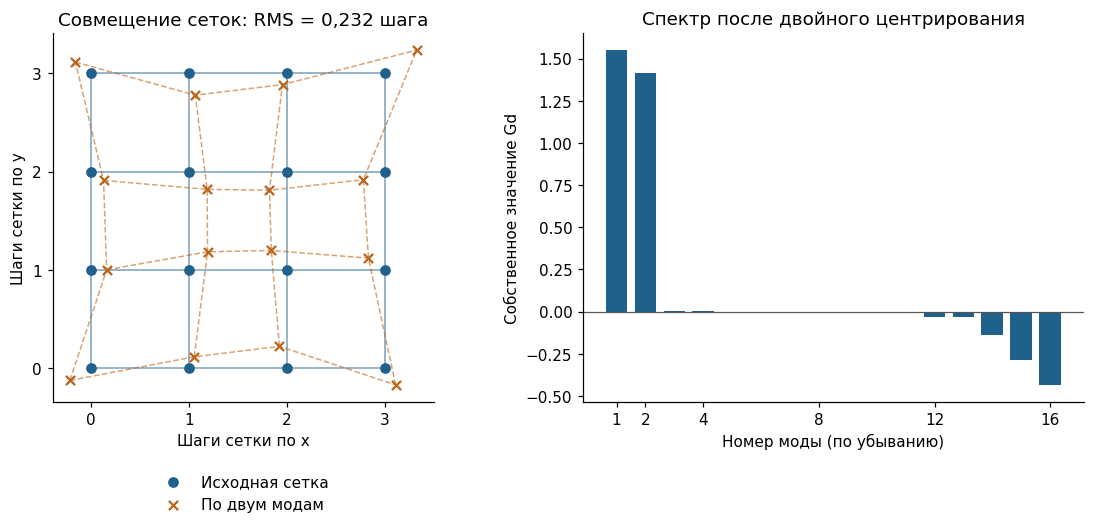

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4.7), layout="constrained")
ax = axes[0]
for grid, color, style in ((X, "#20618C", "-"), (recovered, "#BB661C", "--")):
    for dim in (0, 1):
        for value in np.unique(X[:, dim]):
            take = np.flatnonzero(X[:, dim] == value)
            take = take[np.argsort(X[take, 1 - dim])]
            ax.plot(grid[take, 0], grid[take, 1], style, color=color, alpha=0.6, lw=1)
ax.scatter(*X.T, color="#20618C", marker="o", label=TEXT["original"], zorder=3)
ax.scatter(*recovered.T, color="#BB661C", marker="x", label=TEXT["two_modes"], zorder=4)
ax.set(xlabel=TEXT["grid_x"], ylabel=TEXT["grid_y"], aspect="equal",
       title=TEXT["geometry_title"], xticks=range(4), yticks=range(4))
ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.16))
rank = np.arange(1, 17)
values = eigenvalues[::-1]
axes[1].bar(rank, values, color="#20618C", width=0.75)
axes[1].axhline(0, color="#555555", lw=0.8)
axes[1].set(xlabel=TEXT["mode"], ylabel=TEXT["eigenvalue"],
            title=TEXT["spectrum_title"], xticks=[1, 2, 4, 8, 12, 16])
fig.savefig("electrometry-geometry.svg", bbox_inches="tight")
plt.show()

## Вариация внутренней связи

Четыре электрода $a,b,c,d$ соединены с внутренними вершинами $p,q$: связи $ap,bp,cq,dq$ единичные, связь $pq$ имеет величину $t$. Расчёт проводится при $t=1$. Все величины модельных сетей безразмерны.

Пусть $P$ продолжает потенциалы электродов на все вершины, а $b=e_q-e_p$. Сравниваются две формулы для одной и той же производной:

$$
\frac{dK}{dt}=P^{\mathsf T}bb^{\mathsf T}P
=\frac12 K\frac{dR_{\partial}}{dt}K.
$$

Производная каждого резистенса вычисляется через квадрат скалярного произведения с $(pq)$. Редукция Крона сохраняет резистенсы между электродами, что также проверяется.


[Соответствующая заметка](https://github.com/magin67/pmg-notes/blob/v5/pmg-library/ru/%D0%A0%D0%B5%D0%B7%D0%B8%D1%81%D1%82%D0%B8%D0%B2%D0%BD%D0%B0%D1%8F%20%D0%B3%D0%B5%D0%BE%D0%BC%D0%B5%D1%82%D1%80%D0%B8%D1%8F%20%D0%B8%20%D0%B4%D1%83%D0%B0%D0%BB%D1%8C%D0%BD%D0%BE%D1%81%D1%82%D1%8C/%D0%AD%D0%BB%D0%B5%D0%BA%D1%82%D1%80%D0%BE%D0%BC%D0%B5%D1%82%D1%80%D0%B8%D1%8F/%D0%92%D0%B0%D1%80%D0%B8%D0%B0%D1%86%D0%B8%D0%B8%20%D1%80%D0%B5%D0%B7%D0%B8%D1%81%D1%82%D0%B5%D0%BD%D1%81%D0%BE%D0%B2%20%D0%B2%20%D0%B3%D1%80%D0%B0%D1%84%D0%B5%20%D0%B8%20%D1%81%D0%BF%D0%BB%D0%BE%D1%88%D0%BD%D0%BE%D0%B9%20%D1%81%D1%80%D0%B5%D0%B4%D0%B5.md).

In [8]:
labels = tuple("abcdpq")
bridge = network(labels, [("a", "p", 1), ("b", "p", 1),
                          ("c", "q", 1), ("d", "q", 1), ("p", "q", 1)])
Rb = sp.Matrix(resistance(bridge).value.values)
b = sp.Matrix(segment(bridge, "p", "q").values)
transfer = sp.Matrix(gram(bridge,
    tuple(segment(bridge, labels[i], labels[j]) for i, j in pairs4),
    (segment(bridge, "p", "q"),)).value.values)
dr = -transfer.applyfunc(lambda value: value ** 2)
dR = sp.zeros(4)
for k, (i, j) in enumerate(pairs4):
    dR[i, j] = dR[j, i] = dr[k]
reduced = kron_reduce(bridge, electrodes).value.network
K = sp.Matrix(laplacian(reduced).value.values)
assert sp.Matrix(resistance(reduced).value.values) == Rb[:4, :4]
P = sp.Matrix(dirichlet(bridge, electrodes).value.H.values)
dK_fields = P.T * (b * b.T) * P
dK_resistances = K * dR * K / 2
v = sp.Matrix([1, 1, -1, -1])
assert dK_fields == dK_resistances == v * v.T / 16
print("pair   R(t=1)   dR/dt   c_boundary   dc_boundary/dt")
for k, (i, j) in enumerate(pairs4):
    print(labels[i] + labels[j], Rb[i, j], dr[k], -K[i, j], -dK_fields[i, j])

pair   R(t=1)   dR/dt   c_boundary   dc_boundary/dt
ab 2 0 3/8 -1/16
ac 3 -1 1/8 1/16
ad 3 -1 1/8 1/16
bc 3 -1 1/8 1/16
bd 3 -1 1/8 1/16
cd 2 0 3/8 -1/16


Для пар $ab,cd$ получаются $R=2$ и $dR/dt=0$; для четырёх перекрёстных пар $R=3$ и $dR/dt=-1$. При этом эффективные связи $ab,cd$ уменьшаются с производной $-1/16$, а перекрёстные увеличиваются с производной $1/16$. Изменение одной внутренней связи меняет несколько связей эквивалентной сети.

Следующая проверка использует квадросвязность. На полном наборе шести пар электродов строятся квадратные матрицы $S_{\partial}$ и $L^{(q)}$:

$$
(L^{(q)})_{ij,kl}=\frac12(K_{ik}K_{jl}+K_{il}K_{jk}),
\qquad S_{\partial}L^{(q)}=I,
\qquad dc_{\partial}=-L^{(q)}dR_{\partial}.
$$

Последняя формула восстанавливает изменения **эффективных связей на электродах**. Она не определяет внутреннее устройство среды. Производные дополнительно сравниваются с конечным изменением $t$ на $10^{-5}$.

In [9]:
# Six electrode pairs versus six effective couplings: a square inverse relation.
Gr_boundary = sp.Matrix(green(reduced).value.values)
B = sp.Matrix.hstack(*(sp.eye(4)[:, i] - sp.eye(4)[:, j] for i, j in pairs4))
S_boundary = (B.T * Gr_boundary * B).applyfunc(lambda value: value ** 2)
Lq = sp.Matrix([[(K[i, k] * K[j, l] + K[i, l] * K[j, k]) / 2
                for k, l in pairs4] for i, j in pairs4])
assert S_boundary * Lq == sp.eye(6)
dc = -Lq * dr
assert dc == sp.Matrix([-dK_fields[i, j] for i, j in pairs4])
# Check the derivative against an actual finite conductance change.
step = Q(1, 100000)
changed = vary_conductances(bridge, {("p", "q"): step})
R_changed = sp.Matrix(resistance(changed).value.values)[:4, :4]
K_changed = sp.Matrix(laplacian(kron_reduce(changed, electrodes).value.network).value.values)
error_R = max(abs(value) for value in (R_changed - Rb[:4, :4]) / step - dR)
error_K = max(abs(value) for value in (K_changed - K) / step - dK_fields)
assert error_R < step and error_K < step
print("S_boundary * Lq = I_6:", S_boundary * Lq == sp.eye(6))
print("finite-step derivative errors:", float(error_R), float(error_K))

S_boundary * Lq = I_6: True
finite-step derivative errors: 9.99990000099999e-06 3.1249843750781247e-07


## Восстановление четырёх слоёв

Конечная решётка $4\times4\times4$ содержит 64 вершины и 144 связи между ближайшими соседями. На верхней грани расположены 16 электродов. Используются все 120 модельных резистенсов. Связей за пределами решётки нет; это конечная сеть, а не проверенная аппроксимация бесконечной полусреды.

Четыре положительных параметра $\theta_1,\ldots,\theta_4$ задают проводимости слоёв. Горизонтальная связь равна параметру своего слоя, вертикальная между соседними слоями равна их гармоническому среднему. Матрица $H=\partial c/\partial\theta$ переводит изменения четырёх параметров в изменения 144 связей. Якобиан измерений равен

$$
A=\frac{\partial R}{\partial\theta}=-SH.
$$

`polyform_algebra` строит сеть, вычисляет резистенсы и скалярные произведения. Для многократных шагов подбора используется прямое решение той же системы через SciPy. Его значения и вся матрица $S$ сверяются с пакетом в однородной и заданной неоднородной сети; после подбора резистенсы каждой найденной модели снова проверяются через пакет. Числа в массивах обозначают индексы; вершинам пакета присвоены буквенные имена.


[Соответствующая заметка](https://github.com/magin67/pmg-notes/blob/v5/pmg-library/ru/%D0%A0%D0%B5%D0%B7%D0%B8%D1%81%D1%82%D0%B8%D0%B2%D0%BD%D0%B0%D1%8F%20%D0%B3%D0%B5%D0%BE%D0%BC%D0%B5%D1%82%D1%80%D0%B8%D1%8F%20%D0%B8%20%D0%B4%D1%83%D0%B0%D0%BB%D1%8C%D0%BD%D0%BE%D1%81%D1%82%D1%8C/%D0%AD%D0%BB%D0%B5%D0%BA%D1%82%D1%80%D0%BE%D0%BC%D0%B5%D1%82%D1%80%D0%B8%D1%8F/%D0%92%D0%BE%D1%81%D1%81%D1%82%D0%B0%D0%BD%D0%BE%D0%B2%D0%BB%D0%B5%D0%BD%D0%B8%D0%B5%20%D1%81%D0%B2%D1%8F%D0%B7%D0%B5%D0%B9%20%D0%BF%D1%80%D0%B8%20%D0%B7%D0%B0%D0%B4%D0%B0%D0%BD%D0%BD%D0%BE%D0%B9%20%D1%81%D1%82%D1%80%D1%83%D0%BA%D1%82%D1%83%D1%80%D0%B5%20%D1%81%D0%BE%D1%81%D0%B5%D0%B4%D0%B5%D0%B9.md).

In [10]:
N = 4
XYZ = np.array(list(product(range(N), repeat=3)))
INDEX = {tuple(point): k for k, point in enumerate(XYZ)}
EDGES = []
for i, point in enumerate(XYZ):
    for axis in range(3):
        other = point.copy()
        other[axis] += 1
        if other[axis] < N:
            EDGES.append((i, INDEX[tuple(other)]))
EDGES = np.array(EDGES)
TOP = tuple(map(int, np.flatnonzero(XYZ[:, 2] == 0)))
PAIRS = tuple(combinations(TOP, 2))
GRID_LABELS = tuple((list(ascii_lowercase) +
                    [a + b for a in ascii_lowercase for b in ascii_lowercase])[:len(XYZ)])
LABELED_PAIRS = tuple((GRID_LABELS[i], GRID_LABELS[j]) for i, j in PAIRS)
INC = np.zeros((len(XYZ), len(EDGES)))
for k, (i, j) in enumerate(EDGES):
    INC[i, k], INC[j, k] = 1.0, -1.0
CURRENT = np.zeros((len(XYZ), len(PAIRS)))
for k, (i, j) in enumerate(PAIRS):
    CURRENT[i, k], CURRENT[j, k] = 1.0, -1.0
assert (len(XYZ), len(EDGES), len(TOP), len(PAIRS)) == (64, 144, 16, 120)

def grid_network(c):
    return network(GRID_LABELS,
                   [(GRID_LABELS[i], GRID_LABELS[j], float(value)) for (i, j), value in zip(EDGES, c)],
                   arithmetic="numeric")

def edge_response(c):
    # Fix the last potential to zero; retain all 144 neighboring couplings.
    A, Bcurr = INC[:-1], CURRENT[:-1]
    L_ground = (A * c) @ A.T
    U = cho_solve(cho_factor(L_ground, lower=True), Bcurr)
    R_pairs = np.sum(Bcurr * U, axis=0)
    S = (A.T @ U).T ** 2
    return R_pairs, S

In [11]:
def layer_map(theta):
    c = np.empty(len(EDGES))
    H = np.zeros((len(EDGES), N))
    for k, (i, j) in enumerate(EDGES):
        z, w = XYZ[i, 2], XYZ[j, 2]
        if z == w:
            c[k], H[k, z] = theta[z], 1.0
        else:
            total = theta[z] + theta[w]
            c[k] = 2 * theta[z] * theta[w] / total
            H[k, z] = 2 * theta[w] ** 2 / total ** 2
            H[k, w] = 2 * theta[z] ** 2 / total ** 2
    return c, H

def forward(theta):
    c, H = layer_map(theta)
    R_pairs, S = edge_response(c)
    return R_pairs, -S @ H

Заданная среда имеет параметры $(1;1{,}15;0{,}85;1{,}1)$. Для неё якобиан дополнительно проверяется центральными конечными разностями.

Матрица $S$ имеет размер $120\times144$, а $A$ имеет размер $120\times4$. Сингулярные числа нормированного якобиана $\operatorname{diag}(1/R_0)A$ оценивают различимость изменений слоёв. Они не являются спектром геометрической матрицы $G_d$ из предыдущего расчёта. Здесь $R_0$ обозначает резистенсы однородной сети с $\theta=(1,1,1,1)$.

In [12]:
truth = np.array([1.0, 1.15, 0.85, 1.1])
r0, jac0 = forward(np.ones(N))
rtrue, jac_true = forward(truth)
truth_c, _ = layer_map(truth)
# Validate the fast repeated solves against the package, including the Jacobian.
for c in (np.ones(len(EDGES)), truth_c):
    net = grid_network(c)
    r_fast, s_fast = edge_response(c)
    r_package = np.array(resistance(net, pairs=LABELED_PAIRS).value.values, dtype=float)
    assert np.allclose(r_fast, r_package, rtol=1e-10, atol=1e-12)
    pair_vectors = tuple(segment(net, a, b) for a, b in LABELED_PAIRS)
    edge_vectors = tuple(segment(net, GRID_LABELS[i], GRID_LABELS[j]) for i, j in EDGES)
    s_package = gram(net, pair_vectors, edge_vectors).value.to_numpy() ** 2
    assert np.allclose(s_fast, s_package, rtol=1e-9, atol=1e-12)
h = 1e-5
jac_difference = np.column_stack([
    (forward(truth + h * np.eye(N)[k])[0] - forward(truth - h * np.eye(N)[k])[0]) / (2*h)
    for k in range(N)
])
assert np.max(np.abs(jac_difference - jac_true)) < 1e-8
singular = np.linalg.svd(jac0 / r0[:, None], compute_uv=False)
known_reference = np.r_[np.ones(N - 1), truth[-1]]
jac_three = forward(known_reference)[1][:, :3] / r0[:, None]
singular_three = np.linalg.svd(jac_three, compute_uv=False)
print("S shape:", s_fast.shape, "; A = -S H shape:", jac0.shape)
print("singular values of A / R0:", singular)
print("condition, four parameters:", round(float(singular[0] / singular[-1]), 2))
print("condition, known bottom:", round(float(singular_three[0] / singular_three[-1]), 2))

S shape: (120, 144) ; A = -S H shape: (120, 4)
singular values of A / R0: [8.936209 0.450426 0.022028 0.000983]
condition, four parameters: 9087.93
condition, known bottom: 445.56


У четырёхпараметрической модели отношение наибольшего сингулярного числа к наименьшему равно примерно 9088. При фиксированном нижнем слое оно равно примерно 446; трёхпараметрическая производная вычисляется в точке $(1;1;1;1{,}1)$. Различные значения обусловленности относятся к указанным точкам и одинаковой нормировке строк.

Сравниваются точные данные и данные с независимым нормальным шумом, стандартное отклонение которого равно $0{,}001R_{0,ij}$. Для трёх опытов с шумом используется одна и та же его реализация, `seed=1304`. Во всех случаях $0{,}5\le\theta_i\le1{,}5$. Минимизируется сумма квадратов нормированных невязок; в последнем опыте добавляется штраф $\lambda\sum_i(\theta_i-1)^2$ с $\lambda=1$. Это выбранная для примера сила штрафа, без подбора оптимального значения.

In [13]:
eta = 0.001
noise = eta * r0 * np.random.default_rng(1304).normal(size=len(PAIRS))
observed = rtrue + noise

def fit(observed, scale, fixed_bottom=None, regularization=0.0):
    count = N if fixed_bottom is None else N - 1
    def full_theta(x):
        return x if fixed_bottom is None else np.r_[x, fixed_bottom]
    def residual(x):
        data = (forward(full_theta(x))[0] - observed) / scale
        return np.r_[data, np.sqrt(regularization) * (x - 1)]
    def jacobian(x):
        data = forward(full_theta(x))[1][:, :count] / scale[:, None]
        return np.vstack([data, np.sqrt(regularization) * np.eye(count)])
    result = least_squares(residual, np.ones(count), jac=jacobian, bounds=(0.5, 1.5),
                           method="trf", ftol=1e-12, xtol=1e-12, gtol=1e-12,
                           max_nfev=500)
    assert result.success, result.message
    theta = full_theta(result.x)
    rms = 100 * np.sqrt(np.mean(((forward(theta)[0] - observed) / r0) ** 2))
    return theta, rms

scenarios = [
    ("exact", rtrue, r0, None, 0.0),
    ("noisy", observed, eta * r0, None, 0.0),
    ("known", observed, eta * r0, truth[-1], 0.0),
    ("prior", observed, eta * r0, None, 1.0),
]
fits = {}
print("case     theta_1  theta_2  theta_3  theta_4    RMS, %")
for key, data, scale_fit, bottom, alpha in scenarios:
    theta, rms = fit(data, scale_fit, bottom, alpha)
    fits[key] = (theta, rms)
    print(f"{key:6s}", " ".join(f"{value:8.4f}" for value in theta), f" {rms:.6f}")
    checked = np.array(resistance(grid_network(layer_map(theta)[0]), pairs=LABELED_PAIRS).value.values, dtype=float)
    assert np.allclose(checked, forward(theta)[0], rtol=1e-10, atol=1e-12)
assert np.max(np.abs(fits["exact"][0] - truth)) < 1e-7
assert fits["known"][0][-1] == truth[-1]
assert fits["noisy"][0][-1] > 1.49
assert all(0.09 < fits[key][1] < 0.11 for key in ("noisy", "known", "prior"))

case     theta_1  theta_2  theta_3  theta_4    RMS, %
exact    1.0000   1.1500   0.8500   1.1000  0.000000
noisy    1.0003   1.1462   0.7978   1.5000  0.098280
known    1.0016   1.1278   0.9256   1.1000  0.098447
prior    1.0008   1.1402   0.8364   1.3615  0.098320


| Данные и допущение | $\theta_1$ | $\theta_2$ | $\theta_3$ | $\theta_4$ | RMS невязки, % |
| --- | ---: | ---: | ---: | ---: | ---: |
| Заданная среда | 1,0000 | 1,1500 | 0,8500 | 1,1000 | |
| Точные данные | 1,0000 | 1,1500 | 0,8500 | 1,1000 | $<10^{-10}$ |
| Шум, четыре неизвестных | 1,0003 | 1,1462 | 0,7978 | 1,5000 | 0,098280 |
| Шум, известен нижний слой | 1,0016 | 1,1278 | 0,9256 | 1,1000 | 0,098447 |
| Шум, штраф к фону | 1,0008 | 1,1402 | 0,8364 | 1,3615 | 0,098320 |

Невязка измеряется относительно соответствующих входных данных, с делением каждой пары на $R_{0,ij}$. Точные данные восстанавливают заданные параметры в пределах численной точности. В шумном опыте без дополнительных условий нижний слой достигает верхней границы $1{,}5$. Все три шумных опыта дают почти одинаковую невязку, но заметно разные параметры. Известный нижний слой и штраф меняют допустимые решения; ни один из этих опытов не доказывает общей однозначности обратной задачи.

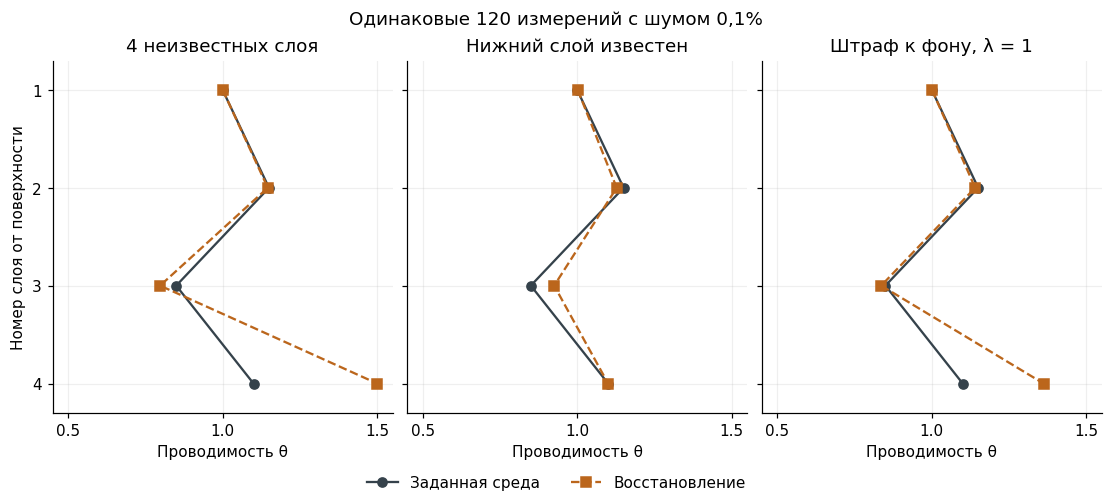

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(10, 4.5), sharex=True, sharey=True, layout="constrained")
for ax, key in zip(axes, ("noisy", "known", "prior")):
    ax.plot(truth, range(1, 5), "o-", color="#35424B", label=TEXT["truth"])
    ax.plot(fits[key][0], range(1, 5), "s--", color="#BB661C", label=TEXT["estimate"])
    ax.set(title=TEXT[key], xlabel=TEXT["conductivity"], xlim=(0.45, 1.55),
           ylim=(4.3, 0.7), xticks=[0.5, 1.0, 1.5], yticks=range(1, 5))
    ax.grid(alpha=0.2)
axes[0].set_ylabel(TEXT["layer"])
handles, labels_legend = axes[0].get_legend_handles_labels()
fig.legend(handles, labels_legend, loc="outside lower center", ncol=2, frameon=False)
fig.suptitle(TEXT["layers_title"])
fig.savefig("electrometry-layers.svg", bbox_inches="tight")
plt.show()

## Что проверено и что остаётся задачей

В блокноте проверены формула четырёх резистенсов, ранг измерений на четырёх электродах, идеальная двумерная геометрия, совмещение реальной сетки, сохранение резистенсов при редукции, две формулы вариации и обратность парных матриц эффективной сети. Якобиан слоистой модели проверен независимо от подбора, а найденные модели пересчитаны через пакет.

Эти примеры не устанавливают число информативных мод реальных данных и минимальный набор полевых измерений. Для таких выводов нужны модель погрешностей, допустимый класс среды и критерий сохранения информации. При изменении исходных данных или модели контрольные числа также потребуется пересмотреть.

Следующий самостоятельный опыт: менять уровень шума или набор измеряемых пар и сравнивать одновременно невязку, ошибку параметров и сингулярные числа якобиана. По одному спектру или одной невязке оценить качество восстановления нельзя.